First 5 Rows:
   Country Name Country Code      Region IncomeGroup  Year  \
0  Afghanistan          AFG  South Asia  Low income  2018   
1  Afghanistan          AFG  South Asia  Low income  2017   
2  Afghanistan          AFG  South Asia  Low income  2016   
3  Afghanistan          AFG  South Asia  Low income  2015   
4  Afghanistan          AFG  South Asia  Low income  2014   

   Birth rate per 1000 people  Death rate per 1000 people  \
0                         NaN                         NaN   
1                      33.211                       6.575   
2                      33.981                       6.742   
3                      34.809                       6.929   
4                      35.706                       7.141   

   Electric power consumption per capita           GDP  GDP per capita  \
0                                    NaN  1.936300e+10         520.897   
1                                    NaN  2.019180e+10         556.302   
2                            

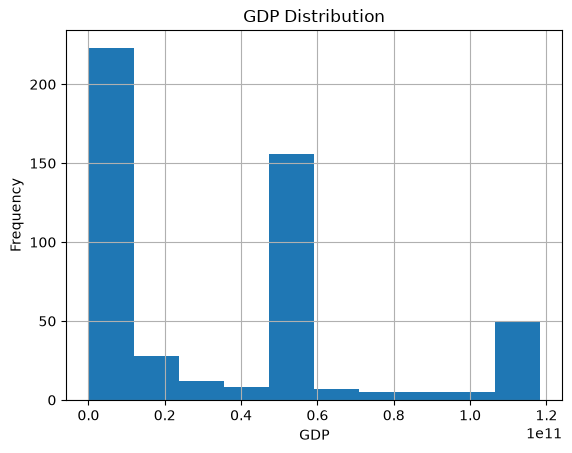

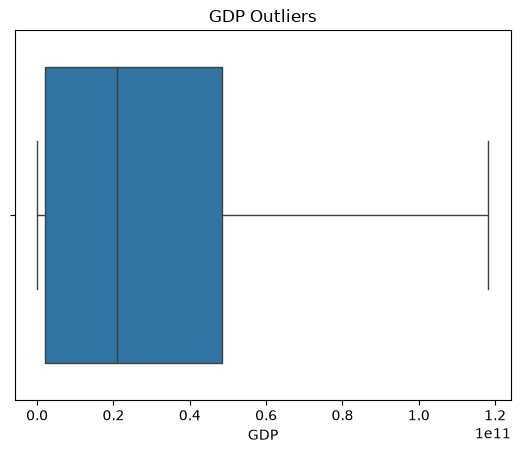

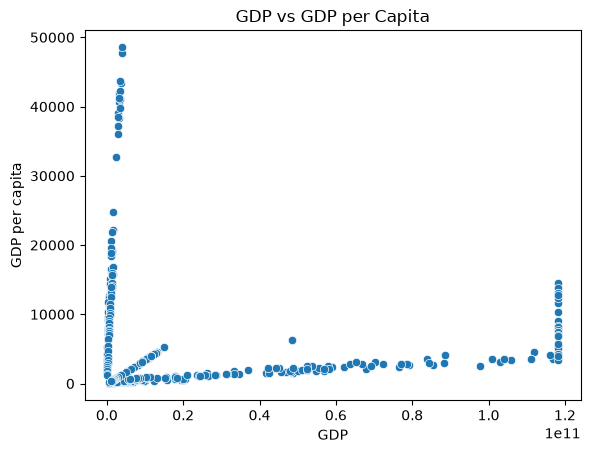

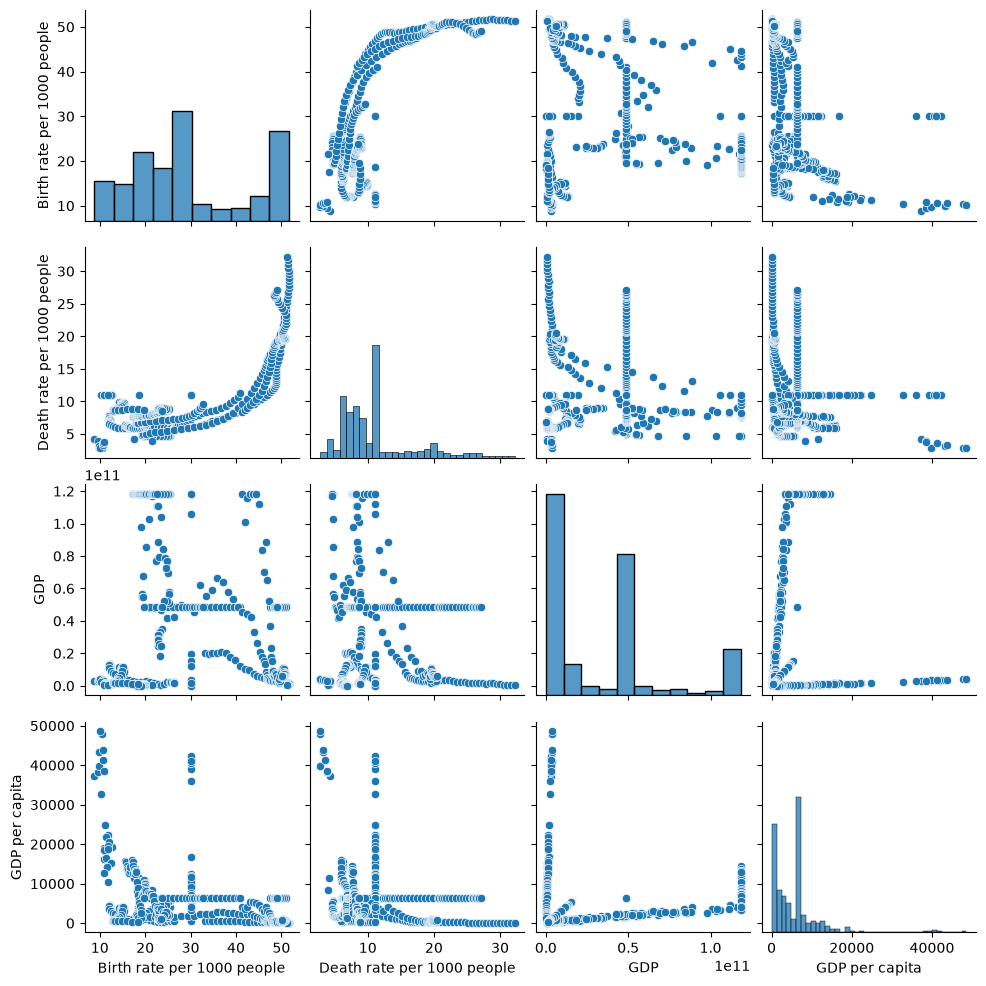

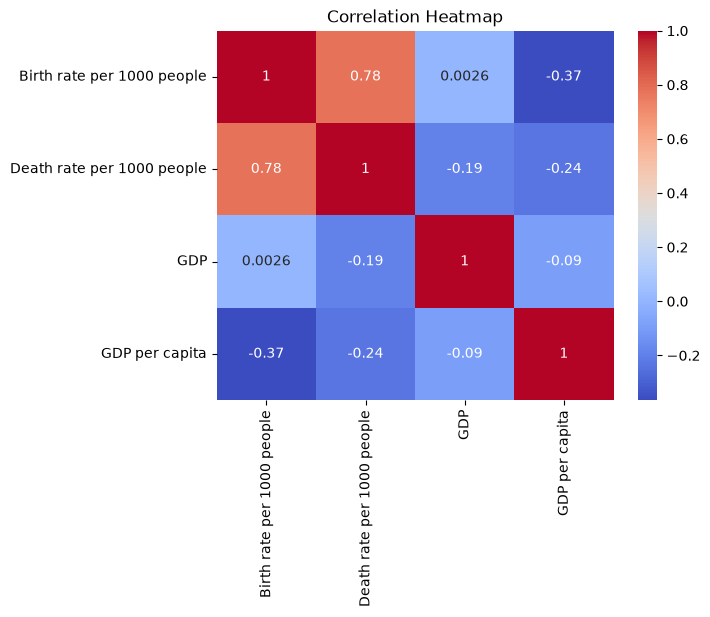

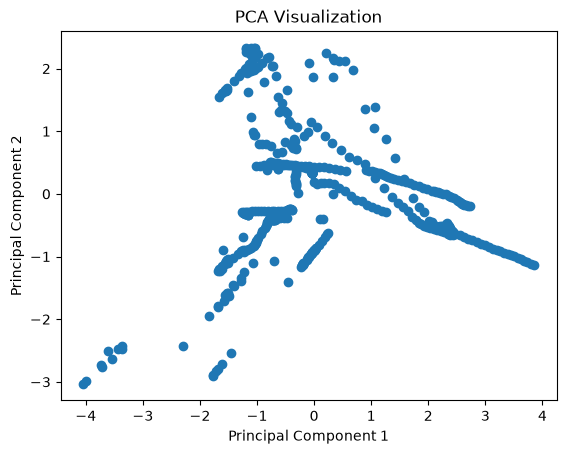

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA

# 1. EXPLORATORY DATA ANALYSIS
df = pd.read_csv("World Economic Indicators - Sheet1.csv")

print("First 5 Rows:\n", df.head())
print("\nDescriptive Statistics:\n", df.describe())
print("\nMissing Values:\n", df.isnull().sum())
print("\nDuplicates:", df.duplicated().sum())

# 2. DATA PREPROCESSING
# Mean Imputation
df = df.fillna(df.mean(numeric_only=True))

# Categorical Encoding
df = pd.get_dummies(df, columns=["Region", "IncomeGroup"], dtype=int)

# 3. OUTLIER DETECTION AND TREATMENT
col = "GDP"

# IQR Method
Q1 = df[col].quantile(0.25)
Q3 = df[col].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print("\nIQR Outliers:")
print(df[(df[col] < lower) | (df[col] > upper)])

# Z-Score Method
z = (df[col] - df[col].mean()) / df[col].std()

print("\nZ-Score Outliers:")
print(df[abs(z) > 3])

# Treat Outliers using IQR
df[col] = df[col].clip(lower, upper)

# 4. FEATURE ENGINEERING
features = [
    "Birth rate per 1000 people",
    "Death rate per 1000 people",
    "GDP",
    "GDP per capita"
]

X = df[features]

# Normalization
minmax = MinMaxScaler()
normalized = minmax.fit_transform(X)
print("\nNormalized Data:\n", normalized[:5])

# Standardization
scaler = StandardScaler()
standardized = scaler.fit_transform(X)
print("\nStandardized Data:\n", standardized[:5])

# PCA
pca = PCA(n_components=2)
pca_result = pca.fit_transform(standardized)

print("\nPCA Results:\n", pca_result[:5])
print("Explained Variance:", pca.explained_variance_ratio_)

# 5. DATA VISUALIZATION

# Histogram
df["GDP"].hist()
plt.title("GDP Distribution")
plt.xlabel("GDP")
plt.ylabel("Frequency")
plt.show()

# Box Plot
sns.boxplot(x=df["GDP"])
plt.title("GDP Outliers")
plt.show()

# Scatter Plot
sns.scatterplot(data=df, x="GDP", y="GDP per capita")
plt.title("GDP vs GDP per Capita")
plt.show()

# Pair Plot
sns.pairplot(df[features])
plt.show()

# Correlation Heatmap
sns.heatmap(df[features].corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

# PCA Visualization
plt.scatter(pca_result[:, 0], pca_result[:, 1])
plt.title("PCA Visualization")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()